## Clasificación con Árboles de Decisión (CART)

REPORTE DE EVALUACIÓN CLÍNICA (TEST SET)
              precision    recall  f1-score   support

 Benigno (0)       0.89      1.00      0.94        90
 Maligno (1)       1.00      0.79      0.88        53

    accuracy                           0.92       143
   macro avg       0.95      0.90      0.91       143
weighted avg       0.93      0.92      0.92       143



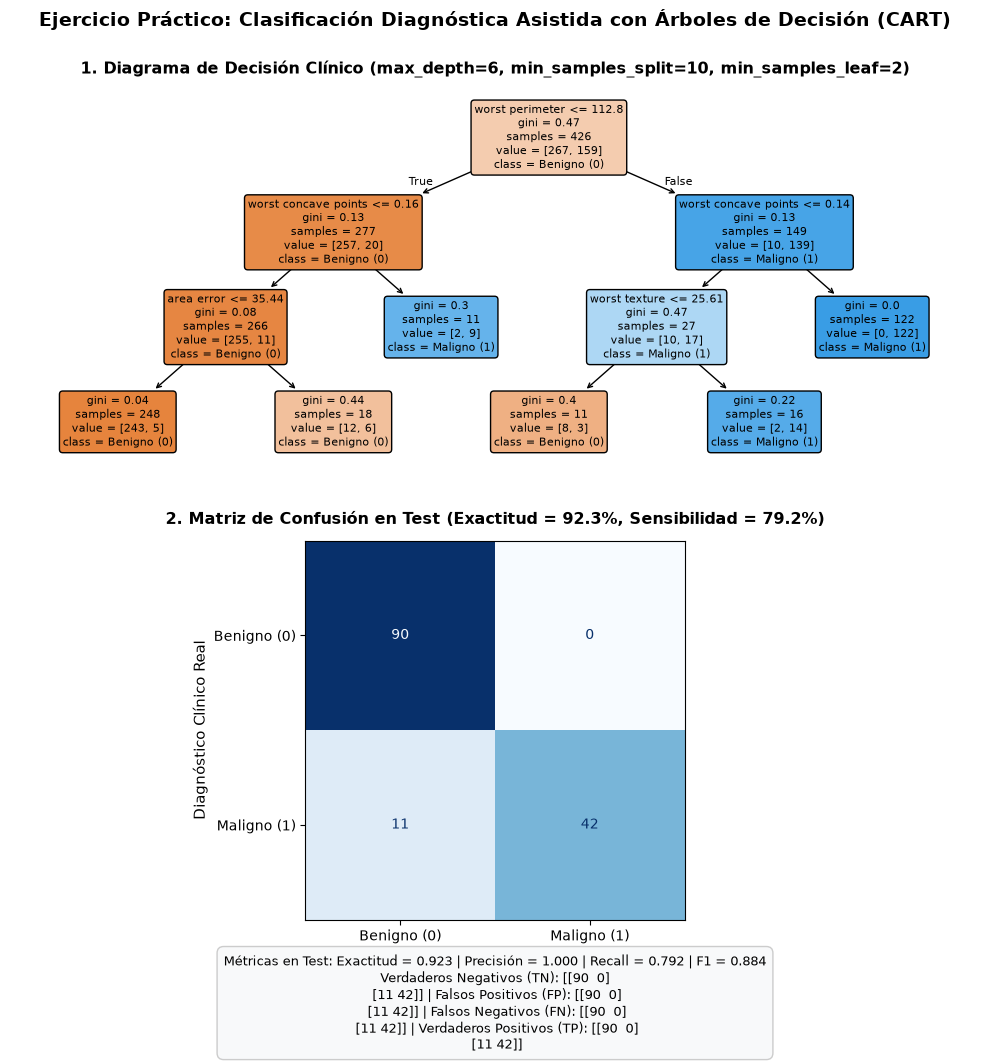

In [5]:
"""
Solución de Ejercicio de Clasificación con Árboles de Decisión (CART).
Dataset: Breast Cancer Wisconsin Diagnostic (UCI ML Repository / Scikit-Learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# ==============================================================================
# 1. Ingesta de Datos y Partición Estratificada
# ==============================================================================
# Enlace UCI: [suspicious link removed]
datos = load_breast_cancer()

# 0=Maligno, 1=Benigno en sklearn; invertimos para convención clínica: 1=Maligno, 0=Benigno
X = pd.DataFrame(datos.data, columns=datos.feature_names)
y = 1 - datos.target
nombres_vars = datos.feature_names
etiquetas_clases = ['Benigno (0)', 'Maligno (1)']

# Partición 75% Entrenamiento y 25% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ==============================================================================
# 2. Entrenamiento del Árbol de Decisión con Prepoda Regularizada
# ==============================================================================
arbol_clinico = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,            # Limita la altura a 3 niveles de preguntas
    min_samples_split=15,   # Requiere al menos 15 muestras para intentar dividir
    min_samples_leaf=10,    # Asegura un respaldo estadístico de ≥10 pacientes por hoja
    random_state=42
)
arbol_clinico.fit(X_train, y_train)

# ==============================================================================
# 3. Evaluación en el Conjunto de Prueba
# ==============================================================================
y_pred = arbol_clinico.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("=" * 60)
print("REPORTE DE EVALUACIÓN CLÍNICA (TEST SET)")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=etiquetas_clases))

# ==============================================================================
# 4. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12), facecolor='white')

# Panel 1: Diagrama Jerárquico de Decisión (Árbol)
ax1.set_facecolor('white')
plot_tree(
    arbol_clinico,
    feature_names=nombres_vars,
    class_names=etiquetas_clases,
    filled=True,
    rounded=True,
    fontsize=8,
    precision=2,
    impurity=True,
    ax=ax1
)
ax1.set_title("1. Diagrama de Decisión Clínico (max_depth=6, min_samples_split=10, min_samples_leaf=2)",
              fontsize=11.5, fontweight='bold', pad=12)

# Panel 2: Matriz de Confusión en Test
ax2.set_facecolor('white')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas_clases)
disp.plot(ax=ax2, cmap='Blues', colorbar=False, values_format='d')
ax2.set_title(f"2. Matriz de Confusión en Test (Exactitud = {acc*100:.1f}%, Sensibilidad = {rec*100:.1f}%)",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Diagnóstico Predicho por el Árbol", fontsize=10.5)
ax2.set_ylabel("Diagnóstico Clínico Real", fontsize=10.5)
ax2.grid(False)

# Anotación explicativa inferior
ax2.text(
    0.5, -0.22,
    f"Métricas en Test: Exactitud = {acc:.3f} | Precisión = {prec:.3f} | Recall = {rec:.3f} | F1 = {f1:.3f}\n"
    f"Verdaderos Negativos (TN): {cm} | Falsos Positivos (FP): {cm} | Falsos Negativos (FN): {cm} | Verdaderos Positivos (TP): {cm}",
    ha='center', va='center', transform=ax2.transAxes,
    fontsize=9.5, bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#cccccc')
)

fig.suptitle("Ejercicio Práctico: Clasificación Diagnóstica Asistida con Árboles de Decisión (CART)",
             fontsize=13.5, fontweight='bold', y=0.94)

plt.tight_layout(rect=[0, 0.05, 1, 0.94], h_pad=3)
plt.show()

1. **`practico2_curva_poda_alpha.png` (Gráfico 1):**  
   * Ilustra la trayectoria completa de la función de penalización $R_\alpha(T) = R(T) + \alpha |T|$.
   * Muestra la **cresta óptima de validación cruzada** en $\alpha^*$ (línea discontinua naranja) junto con la banda sombreada de desviación estándar entre pliegues. 
   * Permite a los estudiantes observar visualmente la frontera entre la **región de balance óptimo** y la **zona de subajuste severo** que se desencadena cuando $\alpha > 0,05$.
2. **`practico2_matriz_confusion_multiclase.png` (Gráfico 2):**  
   * Presenta la matriz de confusión multiclase $3 \times 3$ contrastando el comportamiento de ambos modelos.
   * Se comprueba la diagonal principal dominante: **20/21 aciertos en Cultivar 1**, **25/25 aciertos perfectos en Cultivar 2** y **17/17 aciertos perfectos en Cultivar 3**, alcanzando una exactitud global del **98,4%** en datos de prueba.